# EDA — MIT-BIH Arrhythmia Database
Covers report §2.1–2.5. All statistics come from `ecg.eda.stats` and all figures from `ecg.eda.plots`;
this notebook is the only place that calls them. Run `make prepare` first so the augmentation figure can be drawn.

Outputs (copy by hand into the report when you want to use them):
- CSV tables → `results/eda/*.csv`
- figures → `results/eda/figures/*.png` → copy to `report/figures/`, use with `\includegraphics{name.png}`
- LaTeX tables → `results/eda/tables/*.tex` → copy to `report/tables/`, use with `\input{tables/name}`

In [ ]:
import sys; sys.path.insert(0, '../src')  # noqa: I001
from pathlib import Path

import numpy as np
import pandas as pd

from ecg.config import load_config
from ecg.constants import DS1, DS2, NSTDB_NOISE_RECORDS
from ecg.eda import plots, stats
from ecg.eda.latex import latex_table
from ecg.eda.style import apply_style
from ecg.noise.nstdb import load_noise

cfg = load_config('../configs/preprocess.yaml')
RAW = '../' + cfg['paths']['raw_mitdb']; NST = '../' + cfg['paths']['raw_nstdb']
OUT = Path('../results/eda'); FIG = OUT / 'figures'; TAB = OUT / 'tables'
FIG.mkdir(parents=True, exist_ok=True); TAB.mkdir(parents=True, exist_ok=True)
apply_style(); pd.set_option('display.width', 140)

## 2.1 Dataset description

In [ ]:
recs = stats.load_records(RAW, DS1 + DS2)
leads = stats.lead_table(recs); leads.to_csv(OUT / 'leads.csv')
print(f"records used: {len(recs)}   fs: {leads.fs.unique().tolist()}   samples/record: {leads.samples.unique().tolist()}")
print("first-channel leads:", leads.ch0.value_counts().to_dict())
print("second-channel leads:", leads.ch1.value_counts().to_dict())
leads[leads.ch0 != 'MLII']

records used: 44   fs: [360]   samples/record: [650000]
first-channel leads: {'MLII': 43, 'V5': 1}
second-channel leads: {'V1': 38, 'V2': 2, 'V5': 2, 'V4': 1, 'MLII': 1}


,ch0,ch1,fs,samples
114,V5,MLII,360,650000


## 2.2 Target classes
Raw annotation symbols, then the N/S/V/F mapping with counts per split.

In [ ]:
sym = stats.symbol_counts(recs); sym.to_csv(OUT / 'symbol_counts.csv')
sym.sum().sort_values(ascending=False).to_frame('count').T

,N,L,R,V,A,+,F,~,!,"""",...,x,a,|,E,J,e,Q,[,],S
count,74546,8075,7259,6903,2546,1173,803,573,472,437,...,193,150,131,106,83,16,15,6,6,2


In [ ]:
cc = stats.class_counts(recs); cc.to_csv(OUT / 'class_counts_per_record.csv')
totals = stats.class_totals(cc); totals.to_csv(OUT / 'class_totals.csv')
totals

count                  percent                  
           N     S     V    F       N     S     V     F
split                                                  
DS1    45866   944  3788  415   89.91  1.85  7.43  0.81
DS2    44259  1837  3221  388   89.04  3.70  6.48  0.78
All    90125  2781  7009  803   89.48  2.76  6.96  0.80

## 2.3 Exploratory plots

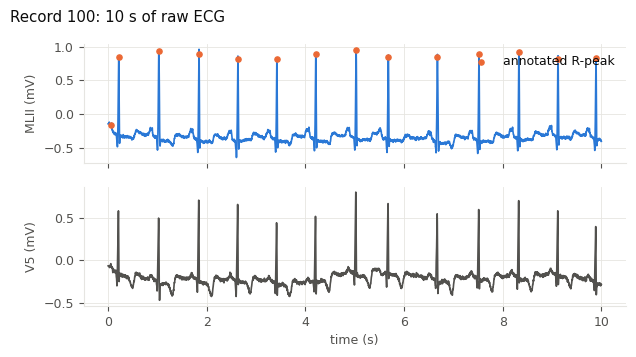

In [ ]:
plots.raw_signal(recs[100]).savefig(FIG / 'eda_raw_ecg.png')

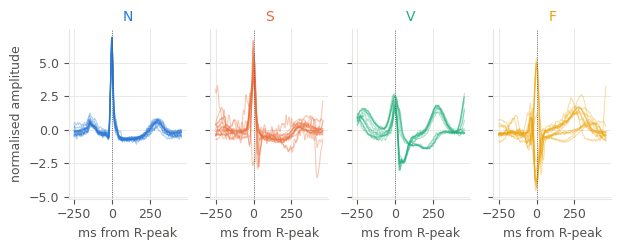

In [ ]:
B, A = cfg['beat']['samples_before'], cfg['beat']['samples_after']
plots.class_examples(recs, cfg['lead'], B, A).savefig(FIG / 'eda_class_examples.png')

In [ ]:
# DS1 records only, so the test set stays unseen.
plots.class_in_context(recs, cfg['lead'], {'N': 101, 'S': 209, 'V': 119, 'F': 208}, B, A, seconds=4.0).savefig(FIG / 'eda_class_context.png')

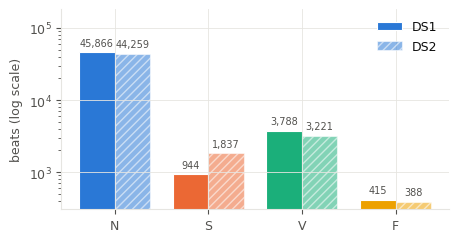

In [ ]:
plots.class_distribution(totals).savefig(FIG / 'eda_class_distribution.png')

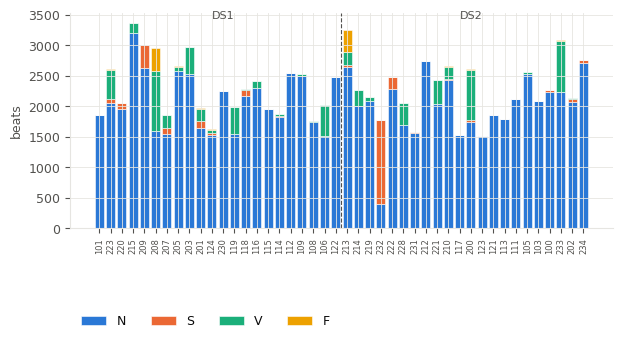

In [ ]:
plots.record_distribution(cc).savefig(FIG / 'eda_record_distribution.png')

,min,max,std,r_peak_median,nan
count,44.000,44.000,44.000,44.000,44.0
mean,-2.641,2.461,0.358,1.067,0.0
std,0.922,0.824,0.122,0.759,0.0
min,-5.120,0.710,0.165,-1.425,0.0
25%,-3.105,2.049,0.271,0.804,0.0
50%,-2.705,2.500,0.342,1.258,0.0
75%,-2.110,2.898,0.416,1.479,0.0
max,-1.120,5.115,0.671,2.205,0.0


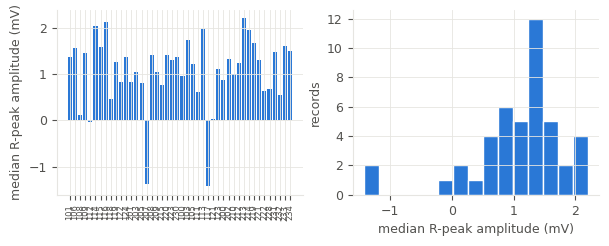

In [ ]:
amp = stats.amplitude_stats(recs, cfg['lead']); amp.to_csv(OUT / 'amplitude.csv')
plots.amplitude_distribution(amp).savefig(FIG / 'eda_amplitude.png')
amp.describe().round(3)

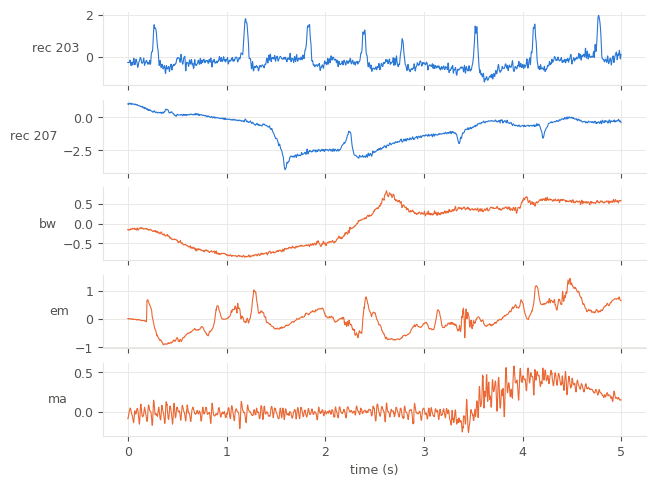

In [ ]:
noise = {k: load_noise(NST, k) for k in NSTDB_NOISE_RECORDS}
plots.noisy_examples([recs[203], recs[207]], noise, cfg['lead'], cfg['fs']).savefig(FIG / 'eda_noisy.png')

In [ ]:
# Figures for report section 3.
plots.beat_window(recs[100], cfg['lead'], B, A).savefig(FIG / 'prep_beat_window.png')
processed = Path('..') / cfg['paths']['processed'] / 'train.npz'
if processed.exists():  # written by `make prepare`
    d = np.load(processed); beat = d['X'][np.flatnonzero(d['y'] == 0)[100], 0]  # the 101st N beat
    plots.amplitude_scale_example(beat, cfg['fs'], B).savefig(FIG / 'aug_amplitude_scale.png')

## 2.4 Data quality

In [ ]:
print("records with NaN samples:", int((amp['nan'] > 0).sum()))
print("amplitude range across records (mV): min", round(amp['min'].min(), 2), " max", round(amp['max'].max(), 2))
print("records that hit the ±5 mV rails:", amp[(amp['min'] <= -4.99) | (amp['max'] >= 4.99)].index.tolist())
noise_marks = stats.noise_annotation_counts(recs); noise_marks.to_csv(OUT / 'noise_marks.csv')
print("records with the most '~' noise annotations:")
noise_marks.sort_values(ascending=False).head(8).to_frame().T

records with NaN samples: 0
amplitude range across records (mV): min -5.12  max 5.12
records that hit the ±5 mV rails: [116]
records with the most '~' noise annotations:


,105,203,200,108,232,106,215,208
noise_marks,88,57,43,41,35,30,30,24


In [12]:
# records that carry most of the rare classes
print("top S records:", cc['S'].sort_values(ascending=False).head(6).to_dict())
print("top F records:", cc['F'].sort_values(ascending=False).head(6).to_dict())

top S records: {232: 1382, 209: 383, 222: 209, 201: 128, 207: 107, 118: 96}
top F records: {208: 373, 213: 362, 223: 14, 205: 11, 233: 11, 210: 10}


## 2.5 Leakage check
Every record belongs to exactly one split, and validation records all come from DS1.

In [13]:
from ecg.data.splits import build_splits, assert_disjoint
splits = build_splits(cfg['records']['validation']); assert_disjoint(splits)
{k: len(v) for k, v in splits.items()}

{'train': 17, 'val': 5, 'test': 22}

## 2.6 Tables for the report
Each cell shows a table and writes it as LaTeX to `results/eda/tables/`.

In [ ]:
# Beats per class in each split, as count (percent).
cnt, pct = totals['count'].astype(int), totals['percent']
t = pd.DataFrame({c: [f"{cnt.loc[s, c]:,} ({pct.loc[s, c]:.1f}%)" for s in cnt.index] for c in cnt.columns})
t = t.apply(lambda col: col.str.replace(',', r'\,').str.replace('%', r'\,\%'))
t.insert(0, 'Split', cnt.index); t['Total'] = cnt.sum(axis=1).values
(TAB / 'eda_class_totals.tex').write_text(latex_table(
    t, 'Beats per class in each split, as count and share of the split.', 'tab:class-totals'))
t

In [ ]:
# Beats per class in every record, DS1 on the left and DS2 on the right.
side = [cc.loc[cc.split == s, ['N', 'S', 'V', 'F']].reset_index().rename(columns={'record': f'{s} record'})
        for s in ('DS1', 'DS2')]
t = pd.concat(side, axis=1)
(TAB / 'eda_class_counts_per_record.tex').write_text(latex_table(
    t, 'Beats per class in each record. DS1 records are on the left, DS2 records on the right.', 'tab:class-per-record', align='YRRRRYRRRR'))
t

In [ ]:
# The ten records with the most noise annotations.
nm = noise_marks.sort_values(ascending=False).head(10)
t = pd.DataFrame({'Record': nm.index, 'Split': cc.loc[nm.index, 'split'].values,
                  r'Noise marks (\texttt{\textasciitilde})': nm.values})
(TAB / 'eda_noise_marks.tex').write_text(latex_table(
    t, r'Records with the most noise annotations (\texttt{\textasciitilde}).', 'tab:noise-marks'))
t

In [ ]:
# Which lead is stored in each channel, and in which records.
g = leads.groupby(['ch0', 'ch1']).apply(lambda d: sorted(d.index))
t = pd.DataFrame({'Channel 1': [k[0] for k in g.index], 'Channel 2': [k[1] for k in g.index],
                  'Records': g.map(len).values, 'Record IDs': g.map(lambda r: ', '.join(map(str, r))).values})
t = t.sort_values('Records', ascending=False)
(TAB / 'eda_leads.tex').write_text(latex_table(
    t, 'Lead stored in each channel, over the 44 records used.', 'tab:leads', align='llrY'))
t